# 90 — Comparison of all binary metaheuristics (UBF) with ANOVA-F and Chi-squared

In [1]:
import sys, warnings, json
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from fsbench import experiment as ex, plots
TAB = ROOT / "results" / "tables"; TAB.mkdir(parents=True, exist_ok=True)
recs = ex.load_all()
df = ex.flatten(recs)
CLASSIC = ["AllFeatures", "ANOVA", "Chi2", "RS"]   # RS = random-search control under the same framework
print(df.method.nunique(), "methods,", len(recs), "runs")

51 methods, 3864 runs


## Main table: mean test metrics over 8 datasets x 6 classifiers x 10 runs

In [2]:
metrics = ["accuracy", "precision_macro", "recall_macro", "f1_macro", "auc_macro", "n_selected", "reduction", "search_time_s"]
overall = df.groupby("method")[metrics].mean()
# rank per (dataset, classifier) block on mean F1, then average (Friedman ranks)
block = df.groupby(["dataset", "classifier", "method"]).f1_macro.mean().unstack()
ranks = block.rank(axis=1, ascending=False)
overall["mean_rank_f1"] = ranks.mean()
overall = overall.sort_values("mean_rank_f1")
overall.round(4).to_csv(TAB / "overall_ranking.csv")
overall.round(4)

,accuracy,precision_macro,recall_macro,f1_macro,auc_macro,n_selected,reduction,search_time_s,mean_rank_f1
method,,,,,,,,,
AllFeatures,0.8701,0.8540,0.8402,0.8394,0.9169,49.7500,0.0000,0.0000,18.3125
INFO,0.8652,0.8453,0.8370,0.8365,0.9097,22.0000,0.5511,8.7155,19.8229
HOA,0.8675,0.8445,0.8375,0.8366,0.9084,30.7375,0.4235,9.1209,20.0729
FATA,0.8655,0.8440,0.8364,0.8352,0.9057,21.5000,0.5686,11.4745,20.0833
PFA,0.8650,0.8451,0.8358,0.8351,0.9085,20.9375,0.5866,20.2126,21.5833
BEO,0.8647,0.8416,0.8351,0.8342,0.9083,21.1375,0.5795,14.4054,21.9167
PLO,0.8648,0.8422,0.8355,0.8346,0.9055,20.3000,0.5810,13.3260,22.0104
WaOA,0.8632,0.8435,0.8341,0.8331,0.9041,23.3250,0.5408,15.8264,22.3958
GWOWOA,0.8628,0.8399,0.8334,0.8325,0.9067,24.7125,0.5094,7.6575,22.4688


In [3]:
chi, p = stats.friedmanchisquare(*[block[c].values for c in block.columns])
print(f"Friedman test over {block.shape[0]} blocks and {block.shape[1]} methods: chi2={chi:.2f}, p={p:.3e}")
meta = [m for m in overall.index if m not in CLASSIC]
FLAGSHIP = meta[0]          # best-ranked wrapper, used as the reference of the Wilcoxon tests below
TOP = meta[:3]              # reported as the top group (no single flagship: differences are not significant)
print("Top group (best mean ranks among the binary metaheuristics):", TOP)
json.dump({"flagship": FLAGSHIP, "top_group": TOP, "friedman_chi2": chi, "friedman_p": p}, open(TAB / "flagship.json", "w"))

Friedman test over 48 blocks and 51 methods: chi2=174.89, p=9.298e-16
Top group (best mean ranks among the binary metaheuristics): ['INFO', 'HOA', 'FATA']


## Wilcoxon signed-rank test: flagship vs every other method (paired over dataset x classifier blocks, Holm correction)

In [4]:
rows = []
for m in block.columns:
    if m == FLAGSHIP: continue
    d = block[FLAGSHIP] - block[m]
    stat, pv = stats.wilcoxon(block[FLAGSHIP], block[m], zero_method="zsplit") if np.any(d != 0) else (np.nan, 1.0)
    rows.append({"method": m, "wins": int((d > 0).sum()), "ties": int((d == 0).sum()), "losses": int((d < 0).sum()), "p_value": pv})
w = pd.DataFrame(rows).sort_values("p_value")
k = len(w); w["p_holm"] = np.minimum(1, np.maximum.accumulate(w.p_value.values * (k - np.arange(k))))
w["significant_0.05"] = w.p_holm < 0.05
w.round(4).to_csv(TAB / "wilcoxon_flagship.csv", index=False)
w.round(4)

,method,wins,ties,losses,p_value,p_holm,significant_0.05
15,EPO,45,0,3,0.0000,0.0000,True
32,MGO,35,0,13,0.0001,0.0025,True
14,EGO,36,0,12,0.0001,0.0029,True
47,WOA,35,0,13,0.0002,0.0091,True
8,CFOA,37,0,11,0.0004,0.0176,True
42,RS,31,0,17,0.0005,0.0224,True
17,FLA,34,0,14,0.0009,0.0410,True
25,HHO,33,0,15,0.0012,0.0530,False
41,RIME,34,0,14,0.0020,0.0824,False
11,DRA,34,0,14,0.0041,0.1662,False


## Pairwise Wilcoxon tests inside the top group and against the classical baselines (Holm per family)

In [5]:
pairs = [(a, b) for i, a in enumerate(TOP) for b in TOP[i + 1:]] + [(a, b) for a in TOP for b in CLASSIC]
rows = []
for a, b in pairs:
    d = block[a] - block[b]
    pv = stats.wilcoxon(block[a], block[b], zero_method="zsplit").pvalue if np.any(d != 0) else 1.0
    rows.append({"A": a, "B": b, "mean_F1_A": block[a].mean(), "mean_F1_B": block[b].mean(),
                 "wins_A": int((d > 0).sum()), "losses_A": int((d < 0).sum()), "p_value": pv})
pw = pd.DataFrame(rows).sort_values("p_value")
k = len(pw); pw["p_holm"] = np.minimum(1, np.maximum.accumulate(pw.p_value.values * (k - np.arange(k))))
pw.round(4).to_csv(TAB / "wilcoxon_top_group.csv", index=False); pw.round(4)

,A,B,mean_F1_A,mean_F1_B,wins_A,losses_A,p_value,p_holm
6,INFO,RS,0.8365,0.8297,31,17,0.0005,0.0075
14,FATA,RS,0.8352,0.8297,35,13,0.0016,0.0227
10,HOA,RS,0.8366,0.8297,33,15,0.0027,0.0356
8,HOA,ANOVA,0.8366,0.8272,28,20,0.0733,0.8797
4,INFO,ANOVA,0.8365,0.8272,27,21,0.0979,1.0000
12,FATA,ANOVA,0.8352,0.8272,31,17,0.1000,1.0000
13,FATA,Chi2,0.8352,0.8263,31,17,0.1234,1.0000
5,INFO,Chi2,0.8365,0.8263,27,21,0.1366,1.0000
9,HOA,Chi2,0.8366,0.8263,27,21,0.1393,1.0000
7,HOA,AllFeatures,0.8366,0.8394,21,27,0.2110,1.0000


## Search quality: does each metaheuristic beat the random-search control?
Compared on the training-CV fitness (lower is better), paired over dataset x run with the same seeds.

In [6]:
fit = pd.DataFrame([{"method": r["method"], "dataset": r["dataset"], "run": r["run"], "fitness": r["best_fitness"],
                     "before_ls": r["history"][-2] if len(r.get("history", [])) > 1 else np.nan}
                    for r in recs if r["method"] not in ("AllFeatures", "ANOVA", "Chi2")])
piv = fit.pivot_table(index=["dataset", "run"], columns="method", values="before_ls")
rows = []
for m in piv.columns:
    if m == "RS": continue
    d = piv["RS"] - piv[m]                      # > 0: the metaheuristic found a better subset than RS
    pv = stats.wilcoxon(piv["RS"], piv[m], zero_method="zsplit").pvalue if np.any(d != 0) else 1.0
    rows.append({"method": m, "mean_fitness_before_LS": piv[m].mean(), "RS_before_LS": piv["RS"].mean(),
                 "wins_vs_RS": int((d > 0).sum()), "losses_vs_RS": int((d < 0).sum()), "p_value": pv})
vs_rs = pd.DataFrame(rows).sort_values("mean_fitness_before_LS")
k = len(vs_rs); o = vs_rs.p_value.values.argsort(); ph = np.empty(k)
ph[o] = np.minimum(1, np.maximum.accumulate(vs_rs.p_value.values[o] * (k - np.arange(k))))
vs_rs["p_holm"] = ph
vs_rs["beats_RS"] = (vs_rs.p_holm < 0.05) & (vs_rs.mean_fitness_before_LS < vs_rs.RS_before_LS)
vs_rs.round(4).to_csv(TAB / "search_vs_random.csv", index=False)
print(int(vs_rs.beats_RS.sum()), "of", k, "metaheuristics beat the random-search control (Holm, 0.05)")
vs_rs.round(4)

38 of 47 metaheuristics beat the random-search control (Holm, 0.05)


,method,mean_fitness_before_LS,RS_before_LS,wins_vs_RS,losses_vs_RS,p_value,p_holm,beats_RS
1,AO,0.1064,0.1385,77,3,0.0000,0.0000,True
31,MGWO,0.1065,0.1385,80,0,0.0000,0.0000,True
21,HGWODE,0.1096,0.1385,76,4,0.0000,0.0000,True
25,IAKMA,0.1101,0.1385,79,1,0.0000,0.0000,True
20,HGS,0.1130,0.1385,74,6,0.0000,0.0000,True
19,GWOWOA,0.1131,0.1385,74,6,0.0000,0.0000,True
36,PSO,0.1131,0.1385,77,3,0.0000,0.0000,True
15,GA,0.1137,0.1385,72,8,0.0000,0.0000,True
37,PSOGWO,0.1145,0.1385,73,7,0.0000,0.0000,True
39,RIME,0.1145,0.1385,73,6,0.0000,0.0000,True


## Per-dataset F1-macro (mean over classifiers and runs): top-10 metaheuristics vs classical filters

In [7]:
top = meta[:10] + CLASSIC
per_ds = df[df.method.isin(top)].groupby(["dataset", "method"]).f1_macro.mean().unstack()[top].round(4)
per_ds.to_csv(TAB / "f1_per_dataset_top10.csv"); per_ds

method,INFO,HOA,FATA,PFA,BEO,PLO,WaOA,GWOWOA,IAKMA,GA,AllFeatures,ANOVA,Chi2,RS
dataset,,,,,,,,,,,,,,
dermatology,0.9619,0.9543,0.9629,0.9613,0.9564,0.9587,0.9543,0.9552,0.9565,0.9588,0.9568,0.9676,0.9568,0.9552
ionosphere,0.8910,0.8825,0.8828,0.8844,0.8836,0.8897,0.8867,0.8862,0.8843,0.8856,0.8907,0.8734,0.8734,0.8765
musk1,0.8701,0.8672,0.8725,0.8665,0.8617,0.8574,0.8688,0.8658,0.8666,0.8637,0.8634,0.8449,0.8603,0.8553
sonar,0.7907,0.8220,0.8007,0.7967,0.8008,0.7953,0.7788,0.7862,0.8031,0.7931,0.8317,0.8293,0.8188,0.7940
spectf,0.5590,0.5421,0.5478,0.5545,0.5449,0.5561,0.5538,0.5425,0.5538,0.5508,0.5448,0.5448,0.5448,0.5471
vehicle,0.7287,0.7278,0.7208,0.7199,0.7275,0.7255,0.7265,0.7256,0.7256,0.7256,0.7311,0.6656,0.6558,0.7273
wdbc,0.9376,0.9424,0.9386,0.9398,0.9391,0.9408,0.9382,0.9410,0.9395,0.9375,0.9442,0.9294,0.9462,0.9291
wine,0.9528,0.9547,0.9557,0.9577,0.9593,0.9534,0.9576,0.9573,0.9524,0.9538,0.9524,0.9628,0.9542,0.9530


In [8]:
for metric in ["recall_macro", "precision_macro", "auc_macro", "accuracy"]:
    t = df[df.method.isin(top)].groupby(["dataset", "method"])[metric].mean().unstack()[top].round(4)
    t.to_csv(TAB / f"{metric}_per_dataset_top10.csv")
    display(t.style.set_caption(metric).highlight_max(axis=1))

method,INFO,HOA,FATA,PFA,BEO,PLO,WaOA,GWOWOA,IAKMA,GA,AllFeatures,ANOVA,Chi2,RS
dataset,,,,,,,,,,,,,,
dermatology,0.961400,0.954100,0.961900,0.959800,0.954700,0.958500,0.953900,0.954600,0.955900,0.957300,0.955900,0.964800,0.955900,0.954500
ionosphere,0.882600,0.872500,0.874700,0.875400,0.873500,0.880400,0.878100,0.877000,0.876300,0.875600,0.882700,0.859800,0.859800,0.868100
musk1,0.873500,0.871200,0.876600,0.870400,0.865000,0.860000,0.873000,0.869800,0.870300,0.867400,0.868000,0.846300,0.862500,0.858800
sonar,0.791300,0.822300,0.801900,0.798300,0.801100,0.796300,0.780400,0.786500,0.804200,0.794700,0.833300,0.830500,0.819800,0.795000
spectf,0.562800,0.550600,0.555500,0.561700,0.555700,0.563800,0.560800,0.551000,0.562400,0.558600,0.547600,0.547600,0.547600,0.557000
vehicle,0.737100,0.735800,0.729500,0.727600,0.735500,0.733600,0.734800,0.733400,0.733500,0.734300,0.739400,0.681400,0.672000,0.735100
wdbc,0.931500,0.936400,0.932300,0.933700,0.933700,0.935200,0.932000,0.935800,0.933500,0.931200,0.938800,0.924300,0.940400,0.922400
wine,0.956200,0.957400,0.958600,0.959900,0.961700,0.956500,0.959700,0.959200,0.955500,0.956400,0.956100,0.964800,0.957800,0.956300


method,INFO,HOA,FATA,PFA,BEO,PLO,WaOA,GWOWOA,IAKMA,GA,AllFeatures,ANOVA,Chi2,RS
dataset,,,,,,,,,,,,,,
dermatology,0.964900,0.956700,0.966600,0.965700,0.961000,0.961100,0.958200,0.958100,0.959900,0.962700,0.959500,0.973100,0.959500,0.959200
ionosphere,0.904400,0.901800,0.896200,0.900000,0.901100,0.905200,0.900200,0.901200,0.896800,0.902500,0.909100,0.896400,0.896400,0.890200
musk1,0.870400,0.868200,0.873100,0.867000,0.862800,0.858500,0.869100,0.866600,0.867200,0.864400,0.865300,0.844800,0.862200,0.856500
sonar,0.795000,0.827700,0.806200,0.803000,0.806400,0.800000,0.784700,0.790600,0.808500,0.800400,0.837500,0.835100,0.821600,0.798900
spectf,0.602700,0.570000,0.588200,0.600800,0.569600,0.587500,0.606500,0.574300,0.594300,0.598200,0.629500,0.629500,0.629500,0.579200
vehicle,0.726700,0.726900,0.718500,0.718200,0.726000,0.723400,0.724900,0.723200,0.723600,0.723000,0.729400,0.670100,0.667600,0.725600
wdbc,0.945700,0.950200,0.947000,0.948000,0.946300,0.948300,0.946400,0.947800,0.947400,0.946000,0.951000,0.935900,0.953500,0.938700
wine,0.952300,0.954600,0.955900,0.957800,0.959500,0.953500,0.957700,0.957200,0.952500,0.953400,0.951000,0.962300,0.953400,0.953100


method,INFO,HOA,FATA,PFA,BEO,PLO,WaOA,GWOWOA,IAKMA,GA,AllFeatures,ANOVA,Chi2,RS
dataset,,,,,,,,,,,,,,
dermatology,0.992300,0.991000,0.992900,0.992100,0.990700,0.992300,0.990200,0.990300,0.991600,0.991500,0.992300,0.991800,0.992300,0.991400
ionosphere,0.944800,0.942200,0.939100,0.938600,0.944500,0.940700,0.940500,0.944800,0.933200,0.942100,0.961200,0.901200,0.901200,0.929800
musk1,0.935100,0.933000,0.933900,0.931500,0.929500,0.925300,0.930300,0.930900,0.929800,0.930400,0.934500,0.919400,0.928900,0.920700
sonar,0.861000,0.886800,0.868500,0.871800,0.871500,0.865200,0.847800,0.865700,0.873500,0.872000,0.904200,0.894200,0.884600,0.870500
spectf,0.696200,0.667300,0.664700,0.686900,0.679900,0.670100,0.674500,0.671400,0.673700,0.671400,0.689100,0.689100,0.689100,0.680000
vehicle,0.900700,0.897600,0.897600,0.896400,0.898600,0.899000,0.899400,0.899700,0.900000,0.900800,0.904500,0.868600,0.857600,0.900400
wdbc,0.967900,0.972100,0.970400,0.970700,0.970900,0.971200,0.969400,0.971600,0.971100,0.969200,0.974200,0.971200,0.970500,0.965800
wine,0.979400,0.977500,0.978500,0.979900,0.981100,0.979900,0.980600,0.978800,0.978800,0.978200,0.974700,0.983400,0.981800,0.980000


method,INFO,HOA,FATA,PFA,BEO,PLO,WaOA,GWOWOA,IAKMA,GA,AllFeatures,ANOVA,Chi2,RS
dataset,,,,,,,,,,,,,,
dermatology,0.966700,0.959500,0.967100,0.965900,0.962700,0.963500,0.959800,0.960800,0.962000,0.964200,0.962100,0.972700,0.962100,0.960600
ionosphere,0.902400,0.896200,0.895100,0.897000,0.896700,0.901700,0.898600,0.898400,0.896200,0.898300,0.904100,0.888400,0.888400,0.889500
musk1,0.871600,0.868600,0.873900,0.867900,0.863400,0.859400,0.870000,0.867200,0.868100,0.865300,0.864800,0.847300,0.862500,0.857100
sonar,0.792600,0.823800,0.802400,0.798400,0.802600,0.796800,0.780700,0.788100,0.804800,0.795000,0.833300,0.830700,0.820100,0.795800
spectf,0.759100,0.756400,0.759500,0.763600,0.755800,0.766900,0.763400,0.754100,0.765800,0.762800,0.757200,0.757200,0.757200,0.759100
vehicle,0.734300,0.732900,0.726700,0.724700,0.732700,0.730800,0.732000,0.730800,0.730800,0.731500,0.736900,0.678500,0.669300,0.732400
wdbc,0.942400,0.946800,0.943400,0.944400,0.943800,0.945300,0.943000,0.945400,0.944200,0.942400,0.948300,0.934700,0.950300,0.934800
wine,0.953100,0.955600,0.956200,0.958000,0.959600,0.953700,0.958000,0.957700,0.952800,0.954300,0.953700,0.963000,0.953700,0.953400


## Per-classifier F1-macro (top group vs classical baselines)

In [9]:
pc = df[df.method.isin(TOP + CLASSIC)].groupby(["classifier", "method"]).f1_macro.mean().unstack().round(4)
pc.to_csv(TAB / "f1_per_classifier_flagship.csv"); pc

method,ANOVA,AllFeatures,Chi2,FATA,HOA,INFO,RS
classifier,,,,,,,
ANN,0.8384,0.8513,0.8365,0.8406,0.8476,0.8521,0.8373
DT,0.7915,0.7857,0.7861,0.7932,0.7872,0.7960,0.7899
KNN,0.8275,0.8291,0.8252,0.8357,0.8329,0.8321,0.8360
RF,0.8365,0.8528,0.8467,0.8446,0.8530,0.8475,0.8399
SVM,0.8197,0.8441,0.8136,0.8427,0.8402,0.8380,0.8294
XGB,0.8496,0.8734,0.8495,0.8545,0.8589,0.8531,0.8456


## Computation: search time, real classifier trainings and memoisation hits

In [10]:
comp = df.drop_duplicates(["method", "dataset", "run"]).groupby("method")[["search_time_s", "n_classifier_fits", "cache_hits", "n_selected"]].mean()
comp["cache_saving_%"] = 100 * comp.cache_hits / (comp.cache_hits + comp.n_classifier_fits).replace(0, np.nan)
comp = comp.loc[overall.index].round(2); comp.to_csv(TAB / "computation.csv"); comp

,search_time_s,n_classifier_fits,cache_hits,n_selected,cache_saving_%
method,,,,,
AllFeatures,0.00,0.00,0.00,49.75,NaN
INFO,8.72,405.84,594.16,22.00,59.42
HOA,9.12,429.90,570.10,30.74,57.01
FATA,11.47,564.45,435.55,21.50,43.56
PFA,20.21,839.06,164.91,20.94,16.43
BEO,14.41,715.45,284.55,21.14,28.46
PLO,13.33,640.33,359.68,20.30,35.97
WaOA,15.83,707.78,312.23,23.32,30.61
GWOWOA,7.66,344.28,655.72,24.71,65.57


## Figures: F1 distribution, convergence, ROC and confusion matrices

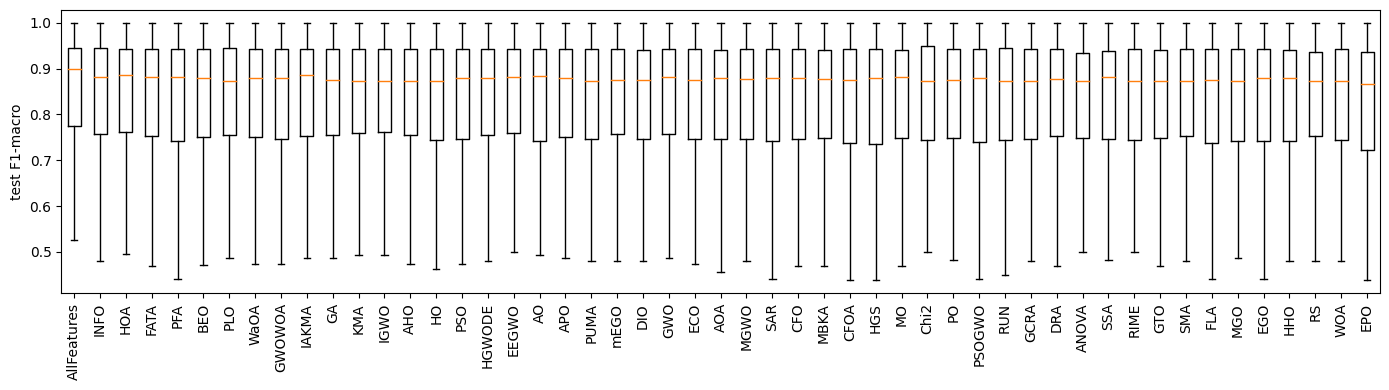

In [11]:
fig, ax = plt.subplots(figsize=(14, 4))
order = list(overall.index)
ax.boxplot([df[df.method == m].f1_macro for m in order], labels=order, showfliers=False)
ax.set_ylabel("test F1-macro"); plt.xticks(rotation=90); plt.tight_layout()
fig.savefig(ROOT / "results/figures/boxplot_f1_all.png", dpi=200)

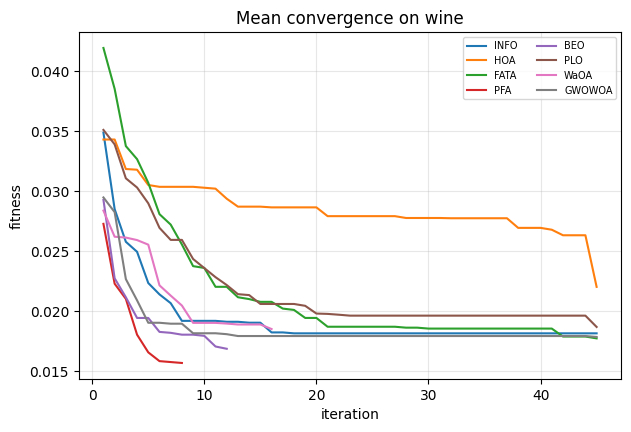

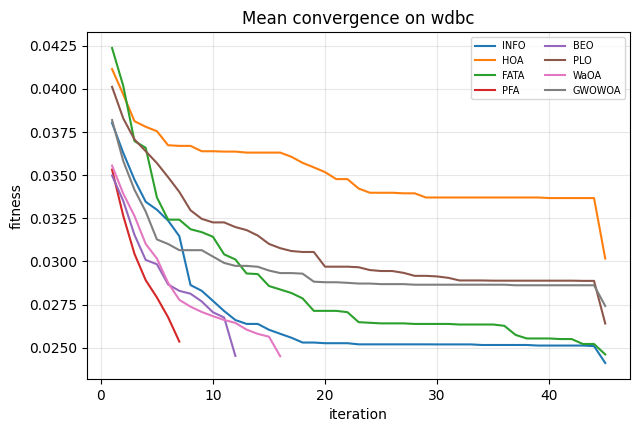

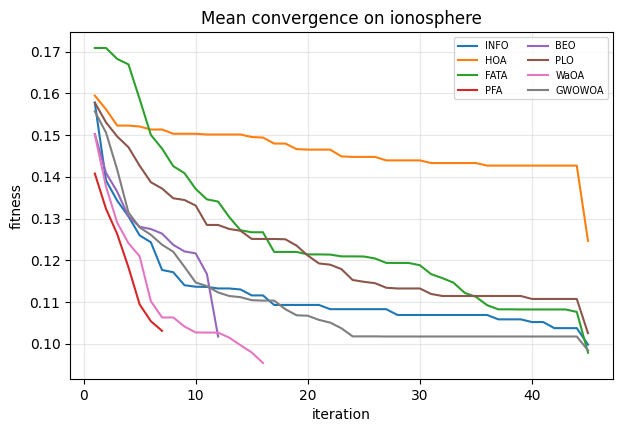

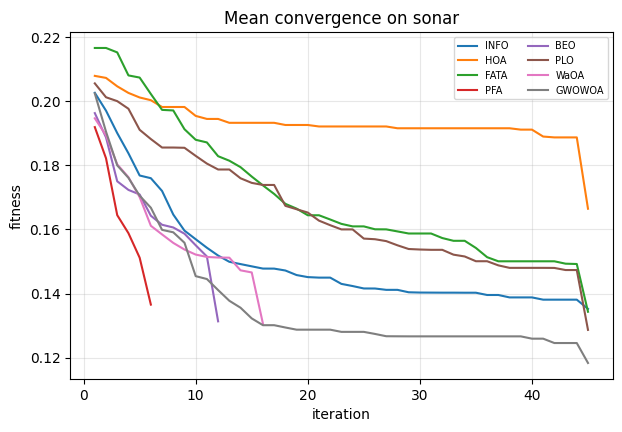

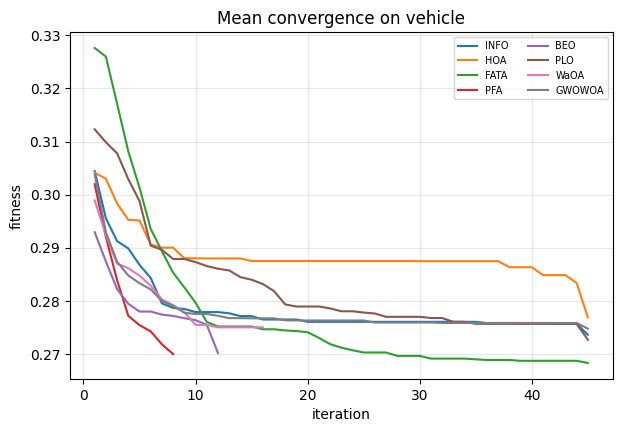

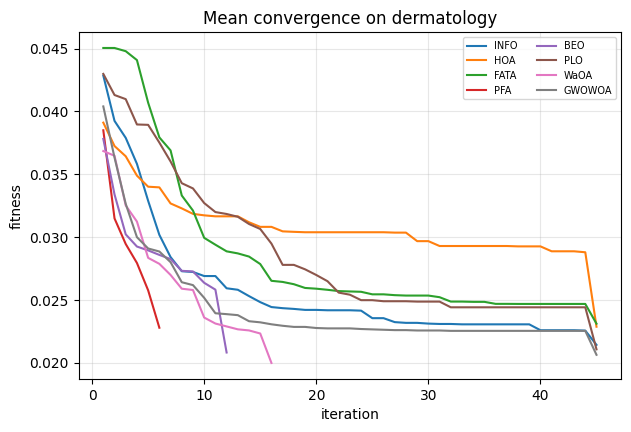

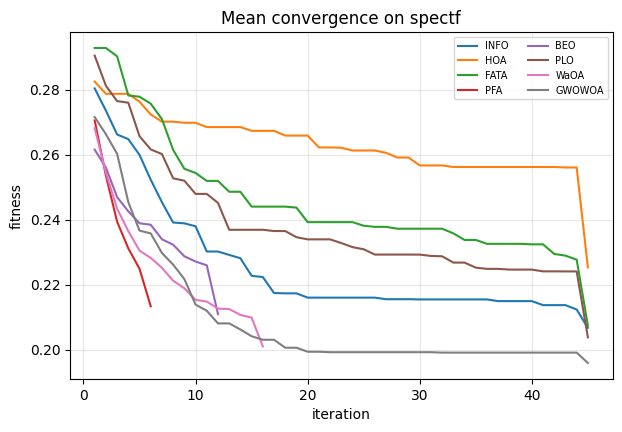

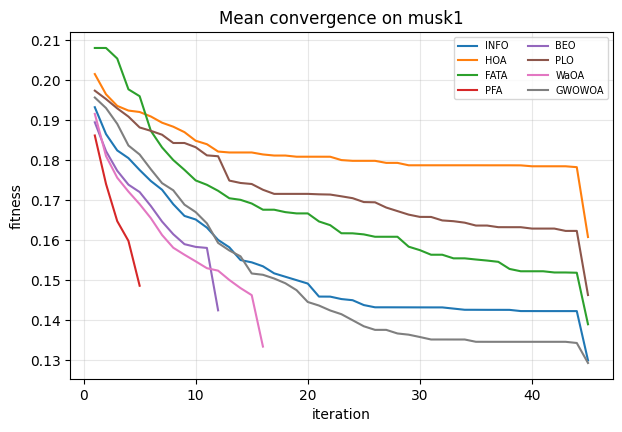

In [12]:
by = {m: [r for r in recs if r["method"] == m] for m in df.method.unique()}
for ds in ex.DATASETS:
    plots.convergence_compare({m: by[m] for m in meta[:8]}, ds, name=f"convergence_top8_{ds}")

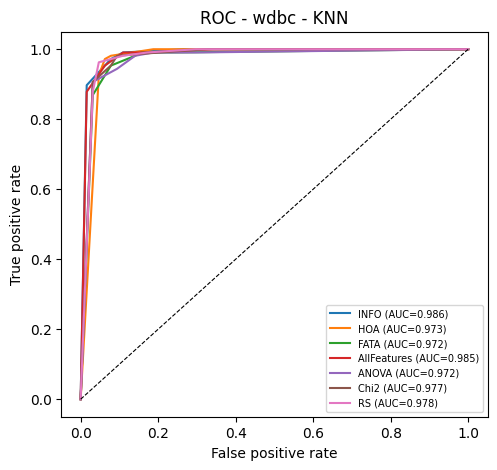

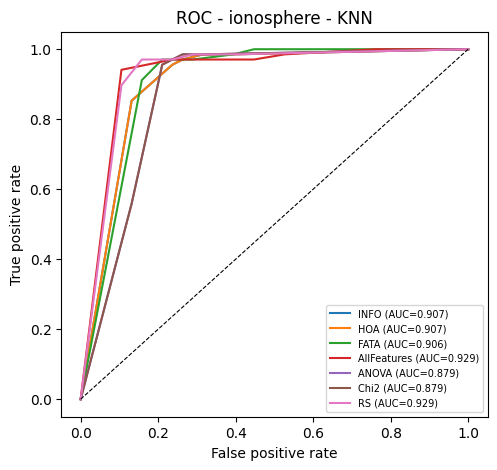

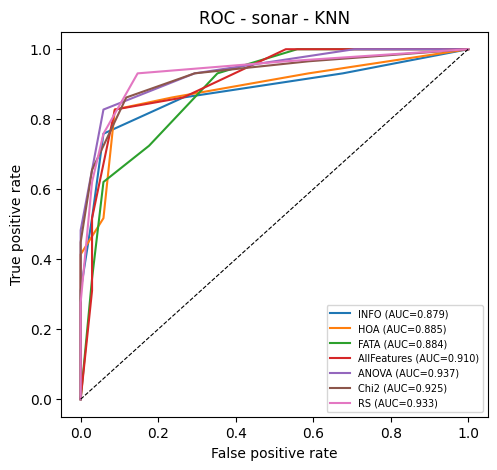

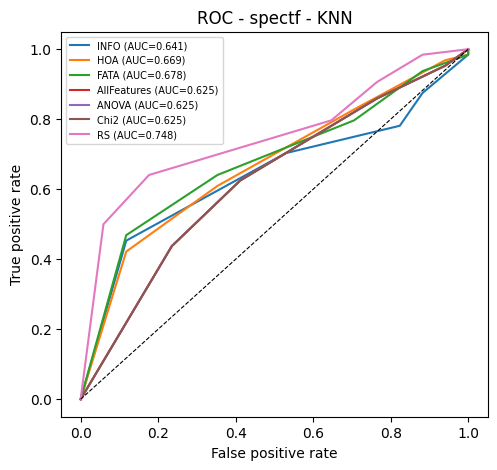

In [13]:
sel = {m: by[m] for m in TOP + CLASSIC}
for ds in ["wdbc", "ionosphere", "sonar", "spectf"]:
    plots.roc_curves(sel, ds, classifier="KNN", name=f"roc_flagship_{ds}")

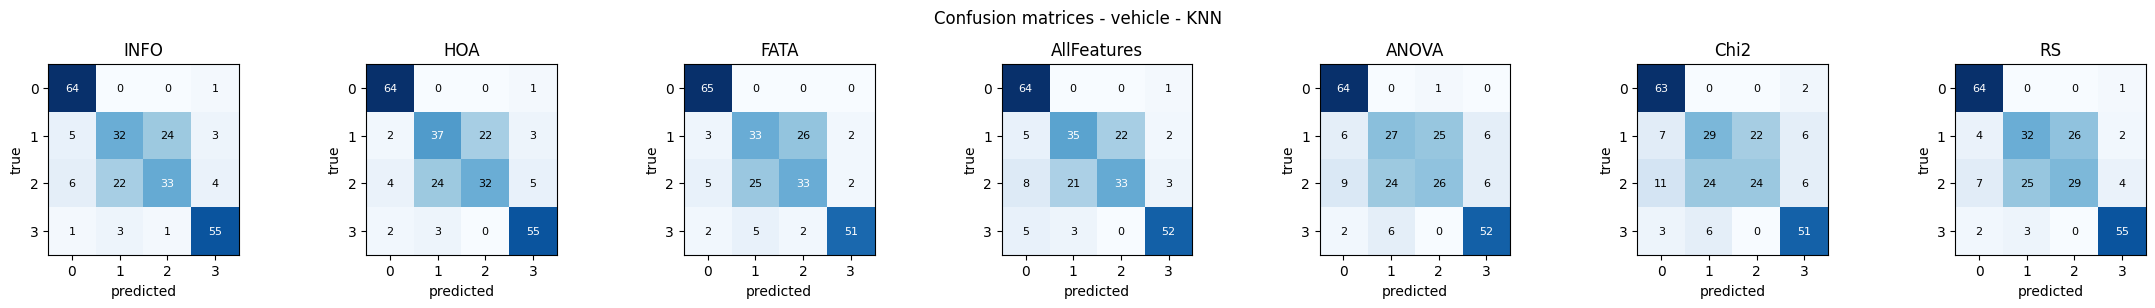

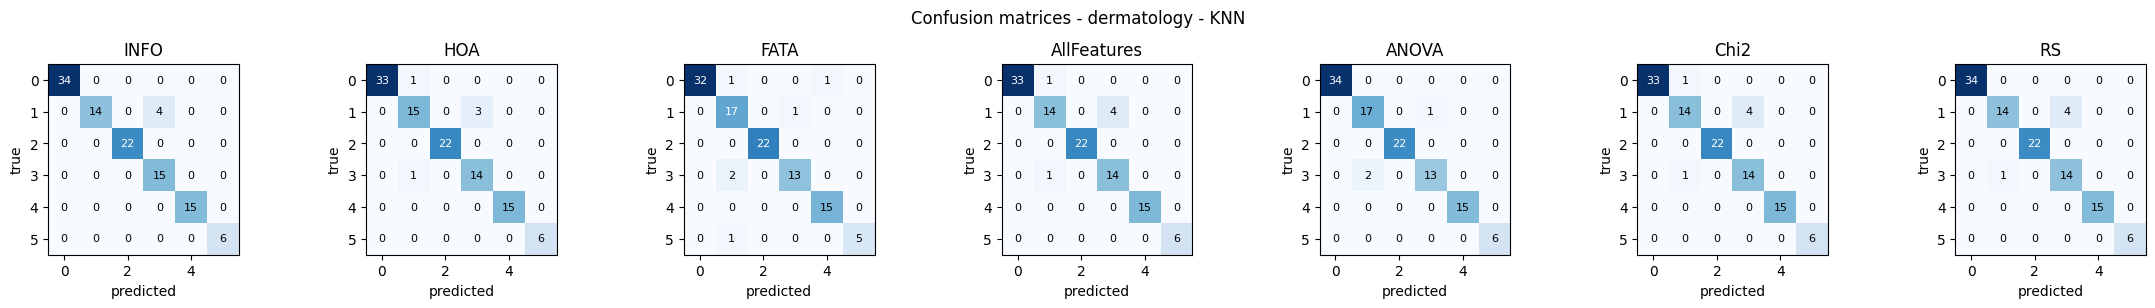

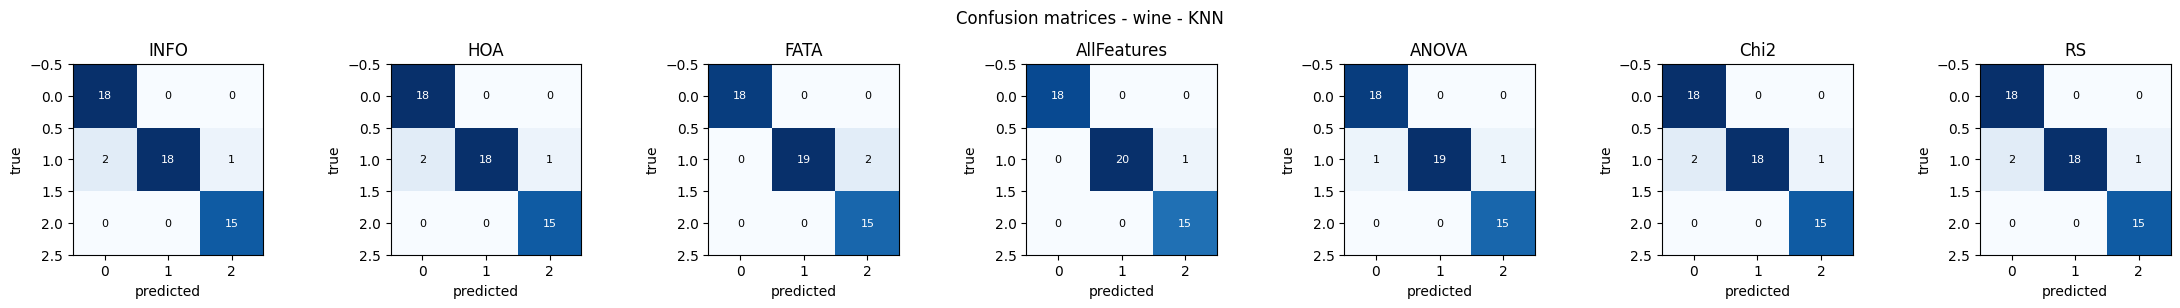

In [14]:
for ds in ["vehicle", "dermatology", "wine"]:
    plots.confusion_matrices(sel, ds, classifier="KNN", name=f"cm_flagship_{ds}")
